📁 Loading data files...
✅ Loaded 3370 events from original data
✅ Loaded 3370 events from interpolated data
🔍 INTERPOLATION ANALYSIS

📊 Event 1 (0008bc71...)
   Original 360° data: 14 players
   Interpolated data: 22 players
   Visible players: 14
   Interpolated players: 8
   Average position difference: 0.00 units

📊 Event 2 (001ed831...)
   Original 360° data: 13 players
   Interpolated data: 22 players
   Visible players: 13
   Interpolated players: 9
   Average position difference: 0.00 units

📊 Event 3 (004df075...)
   Original 360° data: 12 players
   Interpolated data: 23 players
   Visible players: 12
   Interpolated players: 11
   Average position difference: 0.00 units

🎨 Creating comparison plot for event 1...


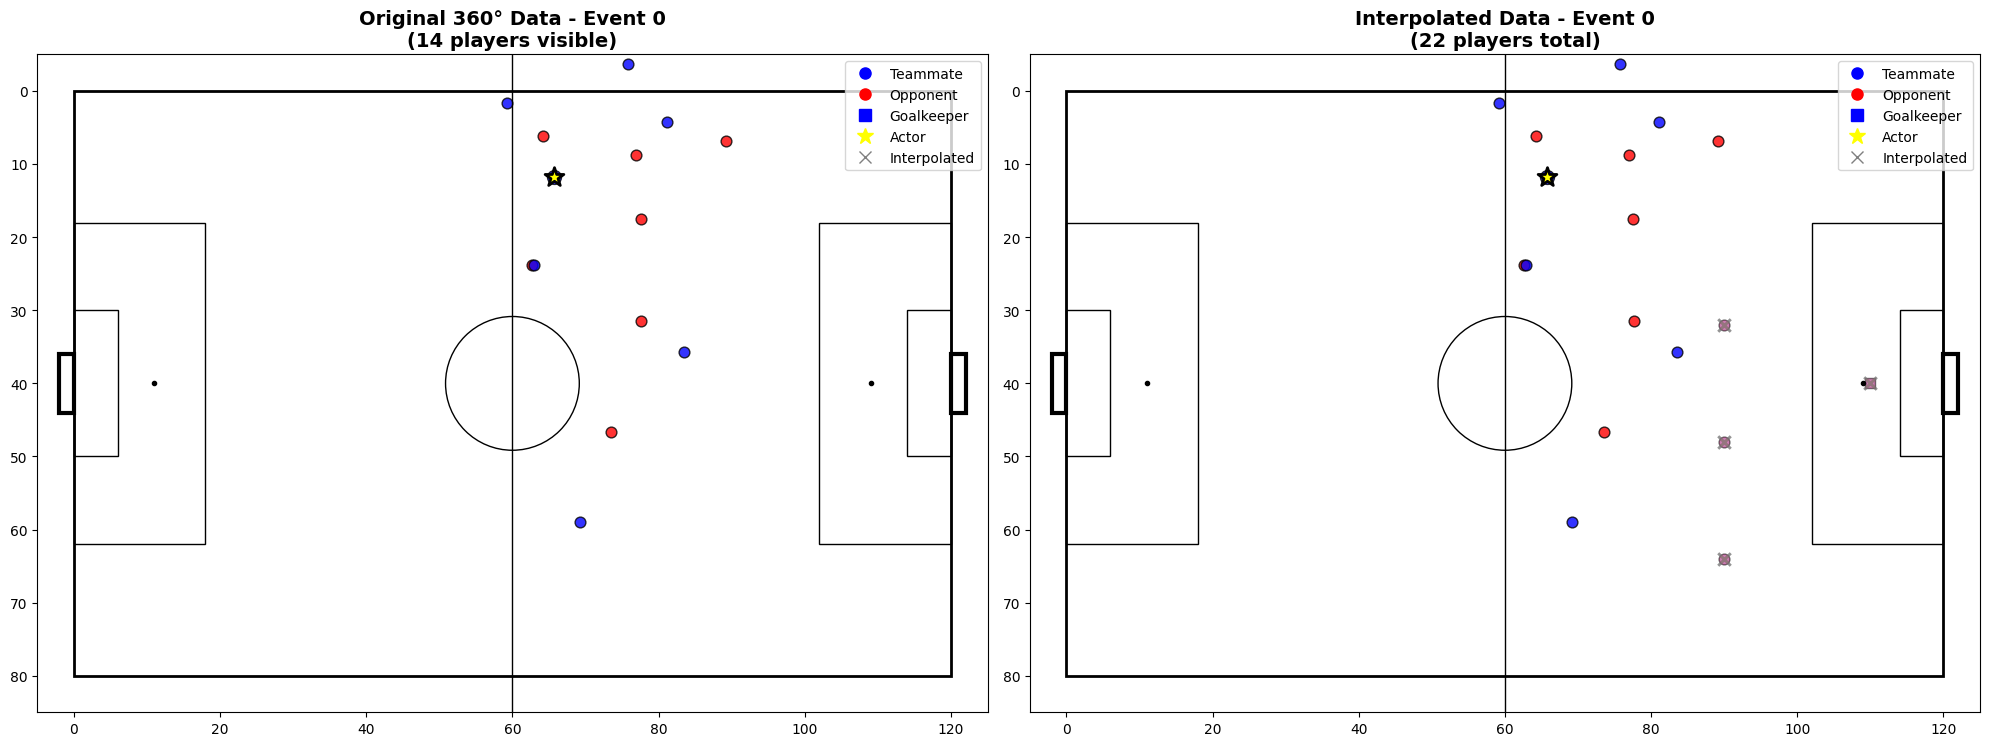


🎨 Creating comparison plot for event 2...


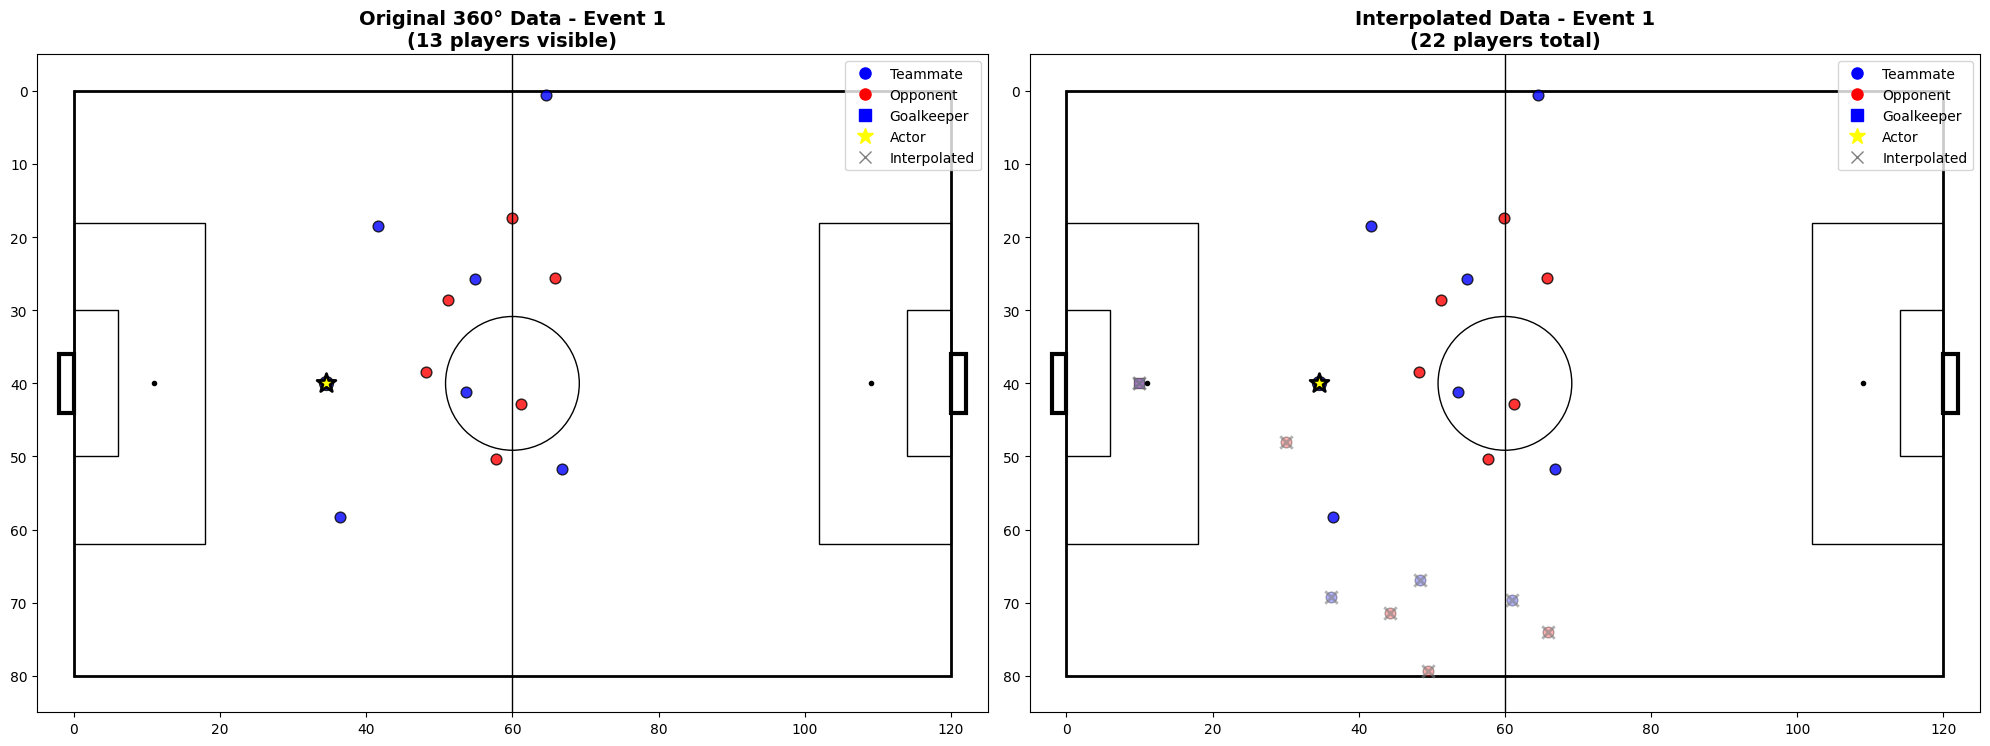


🎨 Creating comparison plot for event 3...


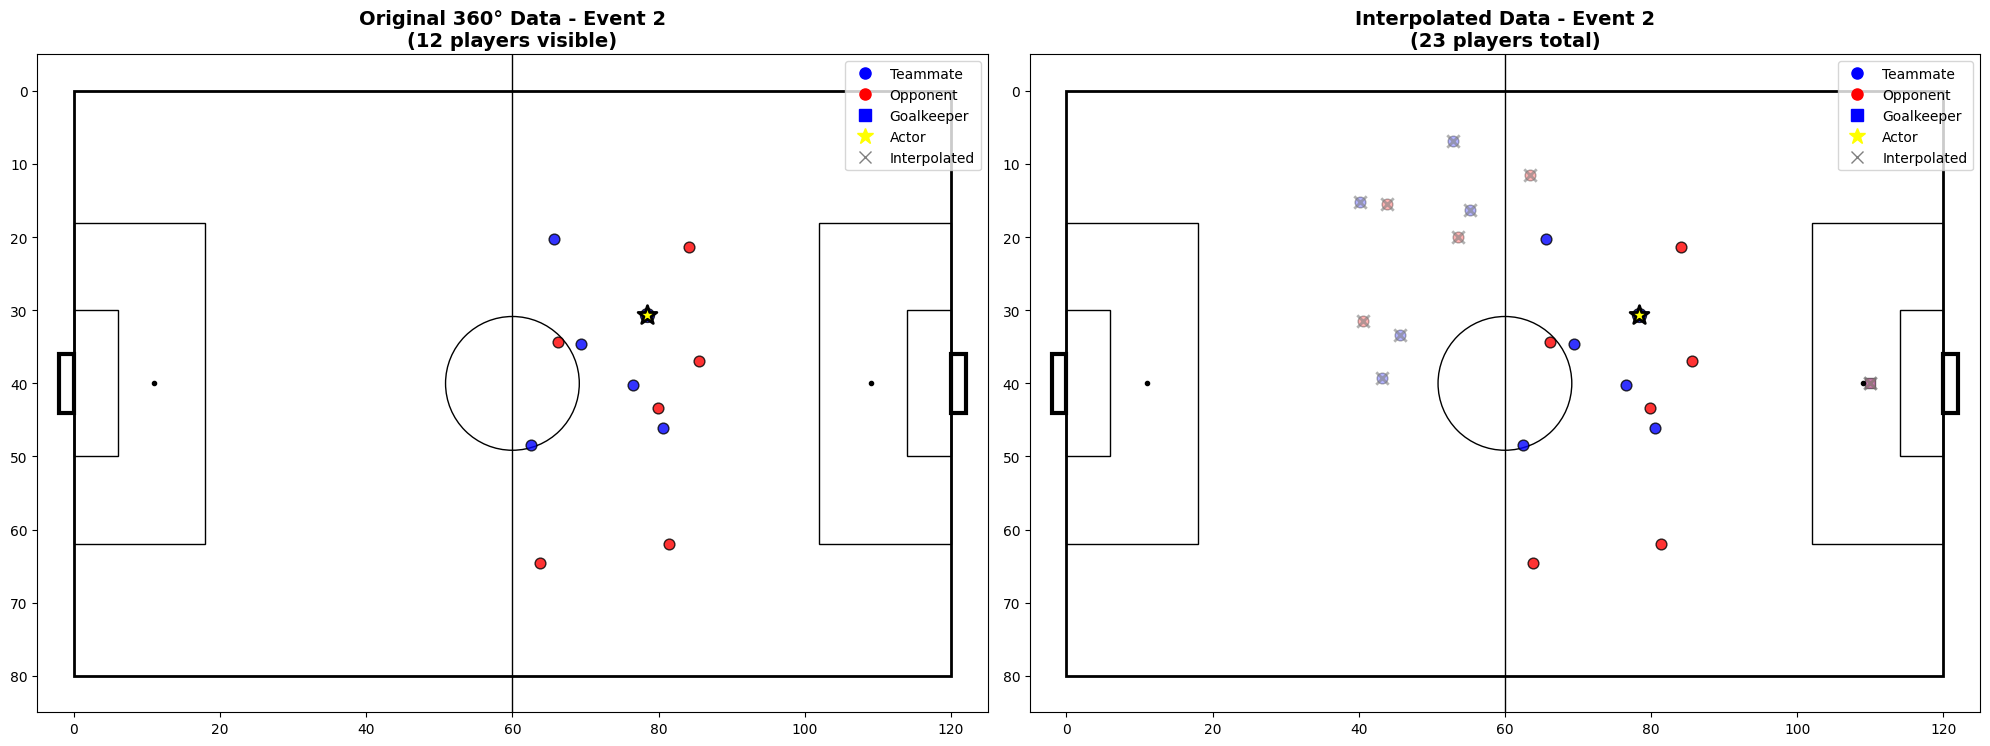


🎨 Creating comparison plot for event 4...


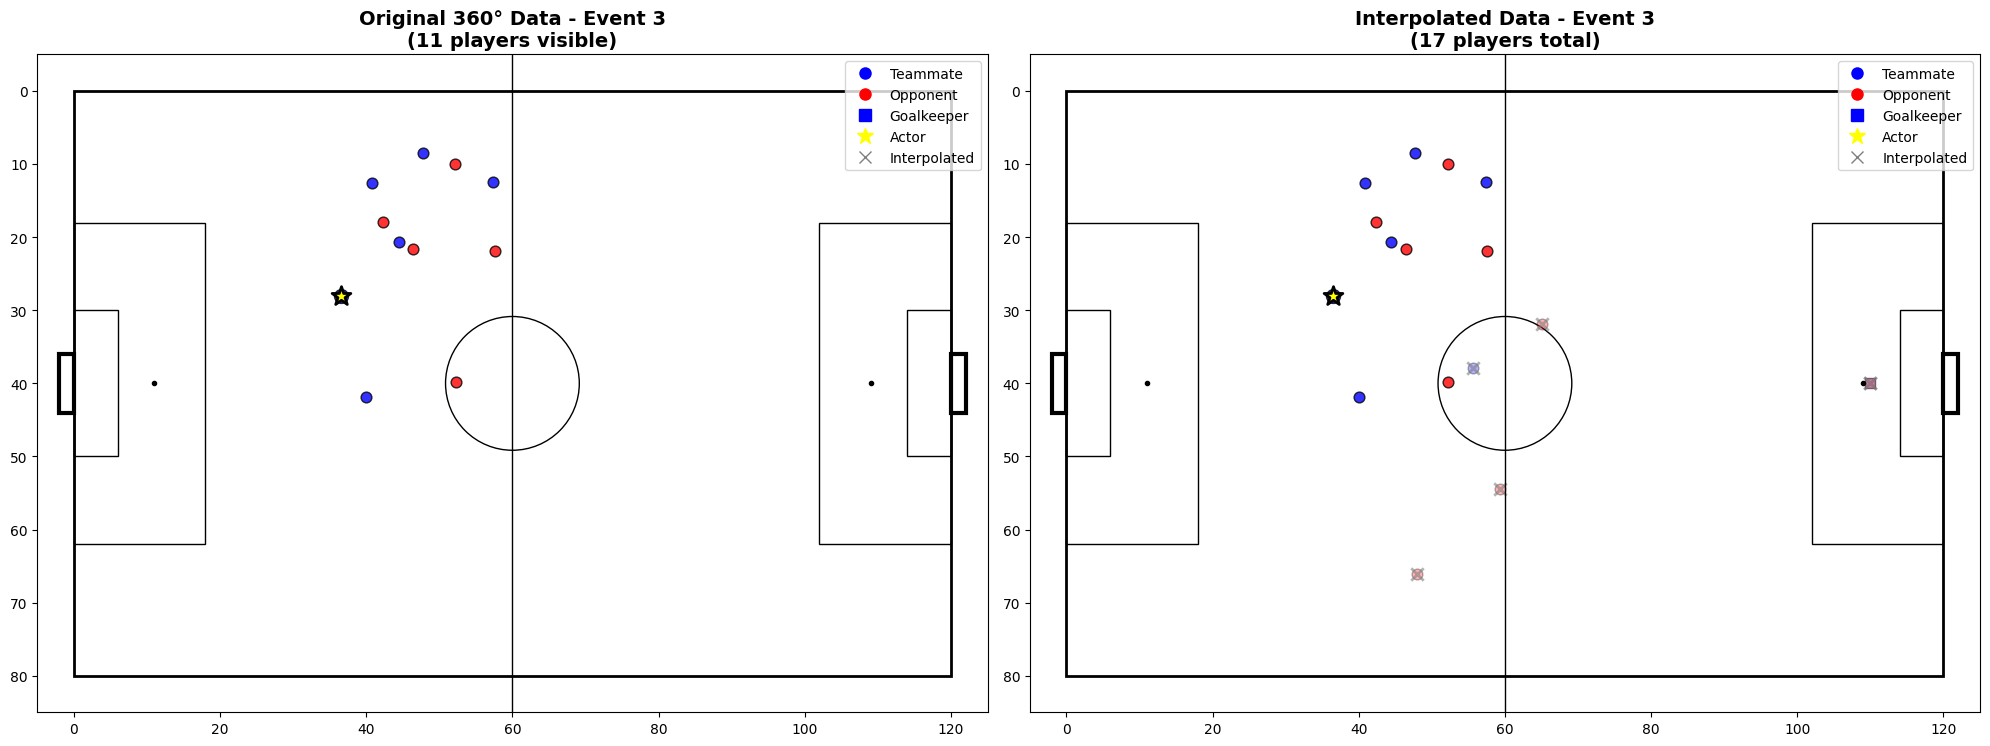


🎨 Creating comparison plot for event 5...


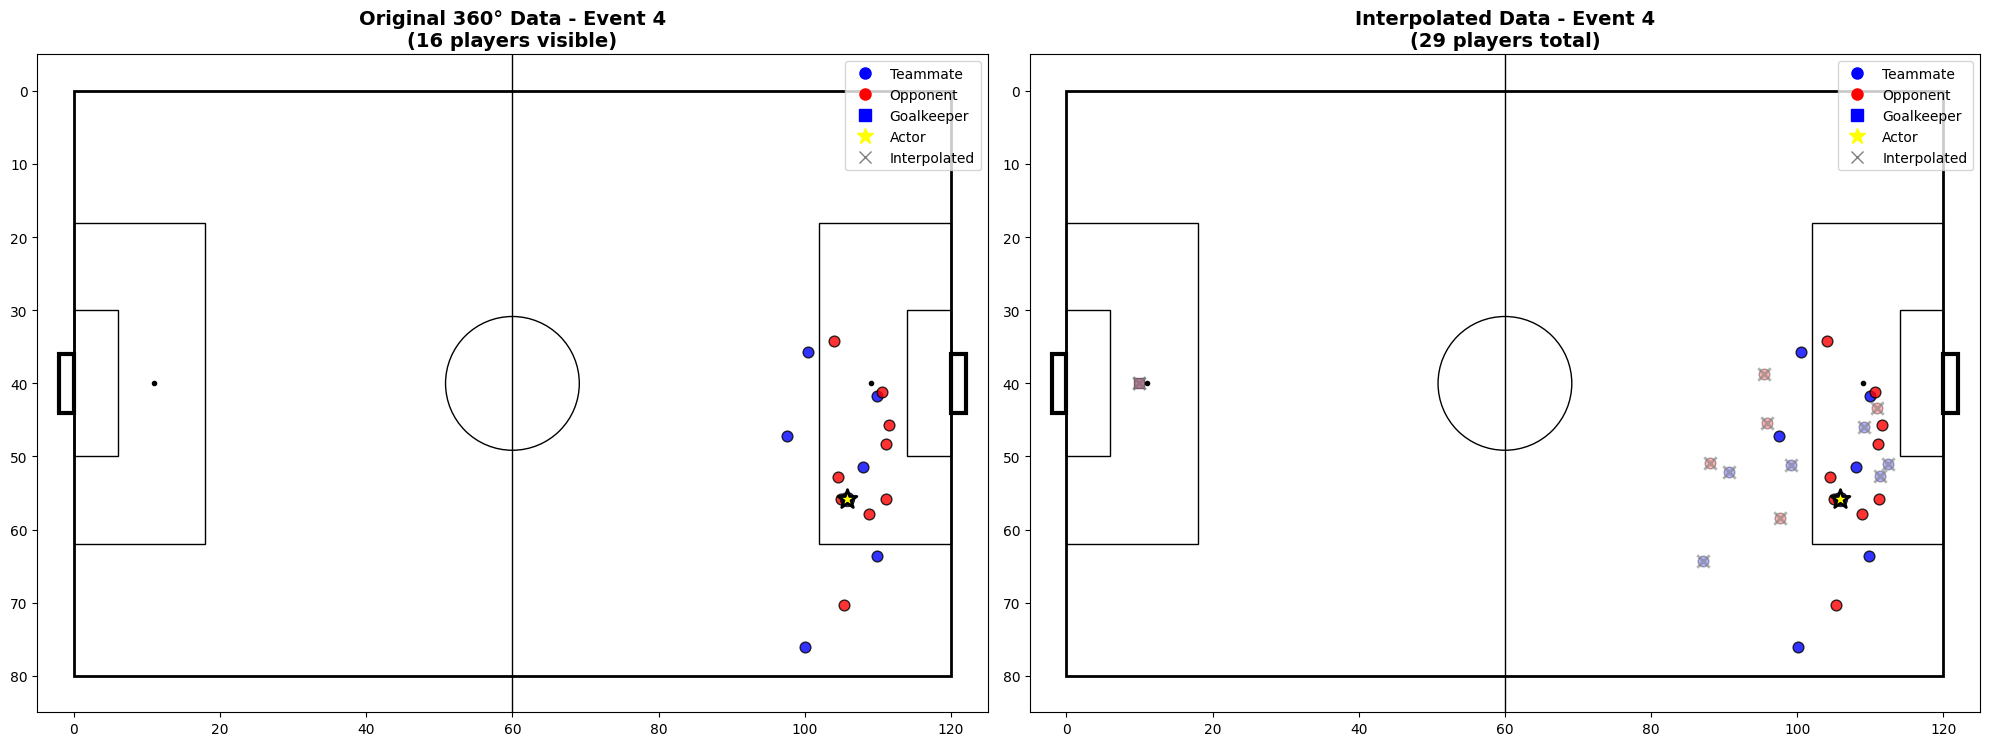


🎨 Creating comparison plot for event 6...


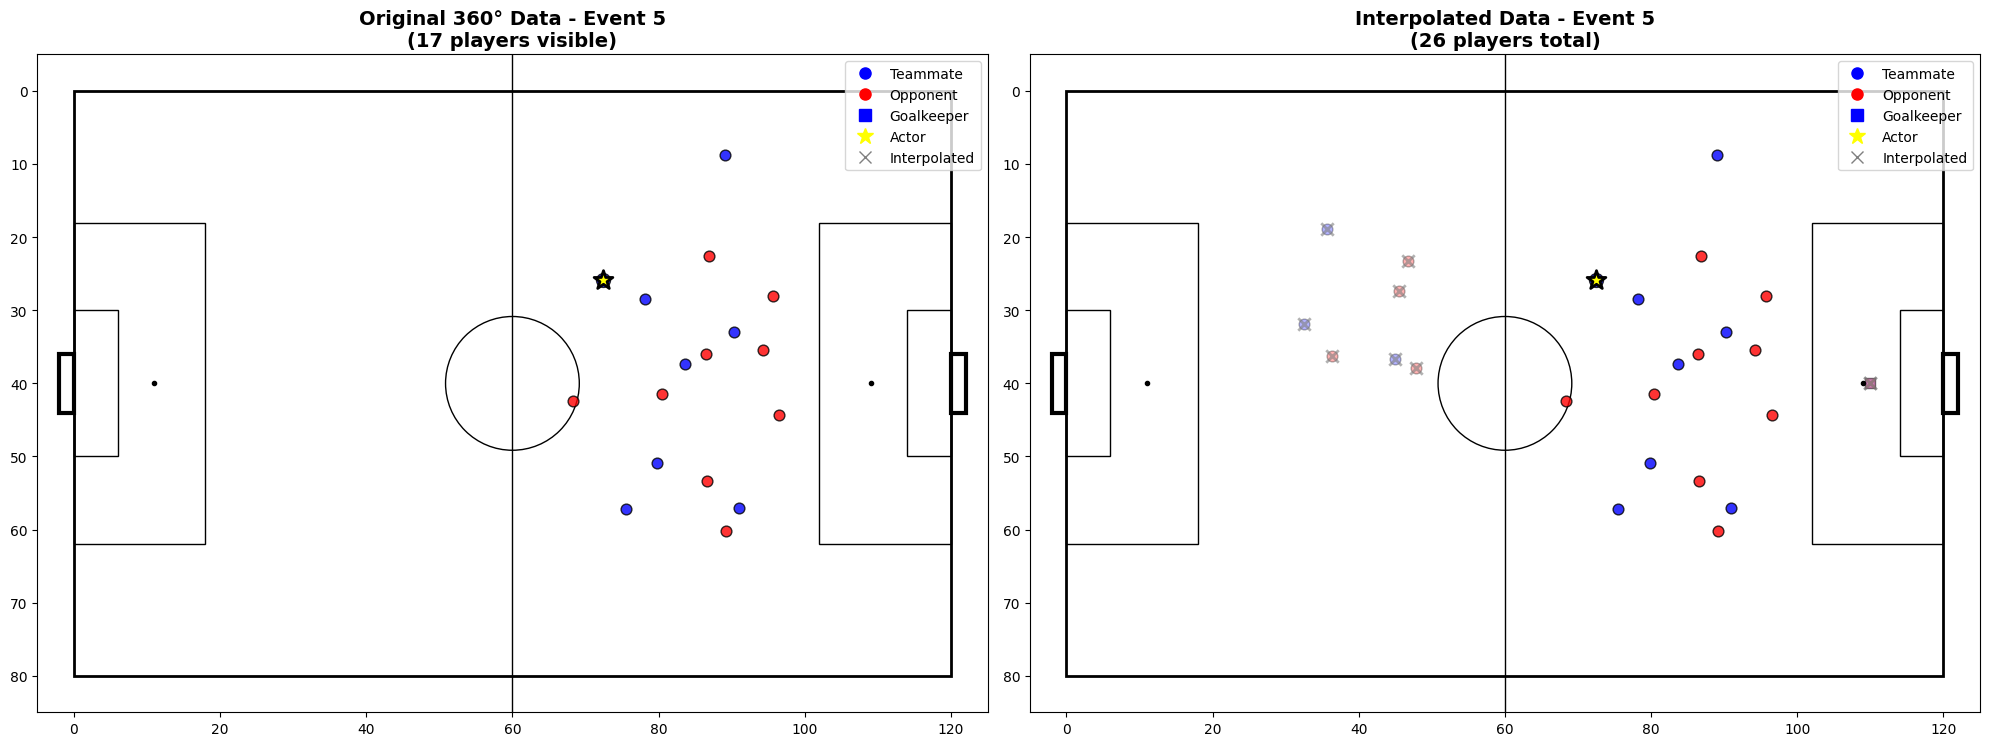


🎨 Creating comparison plot for event 7...


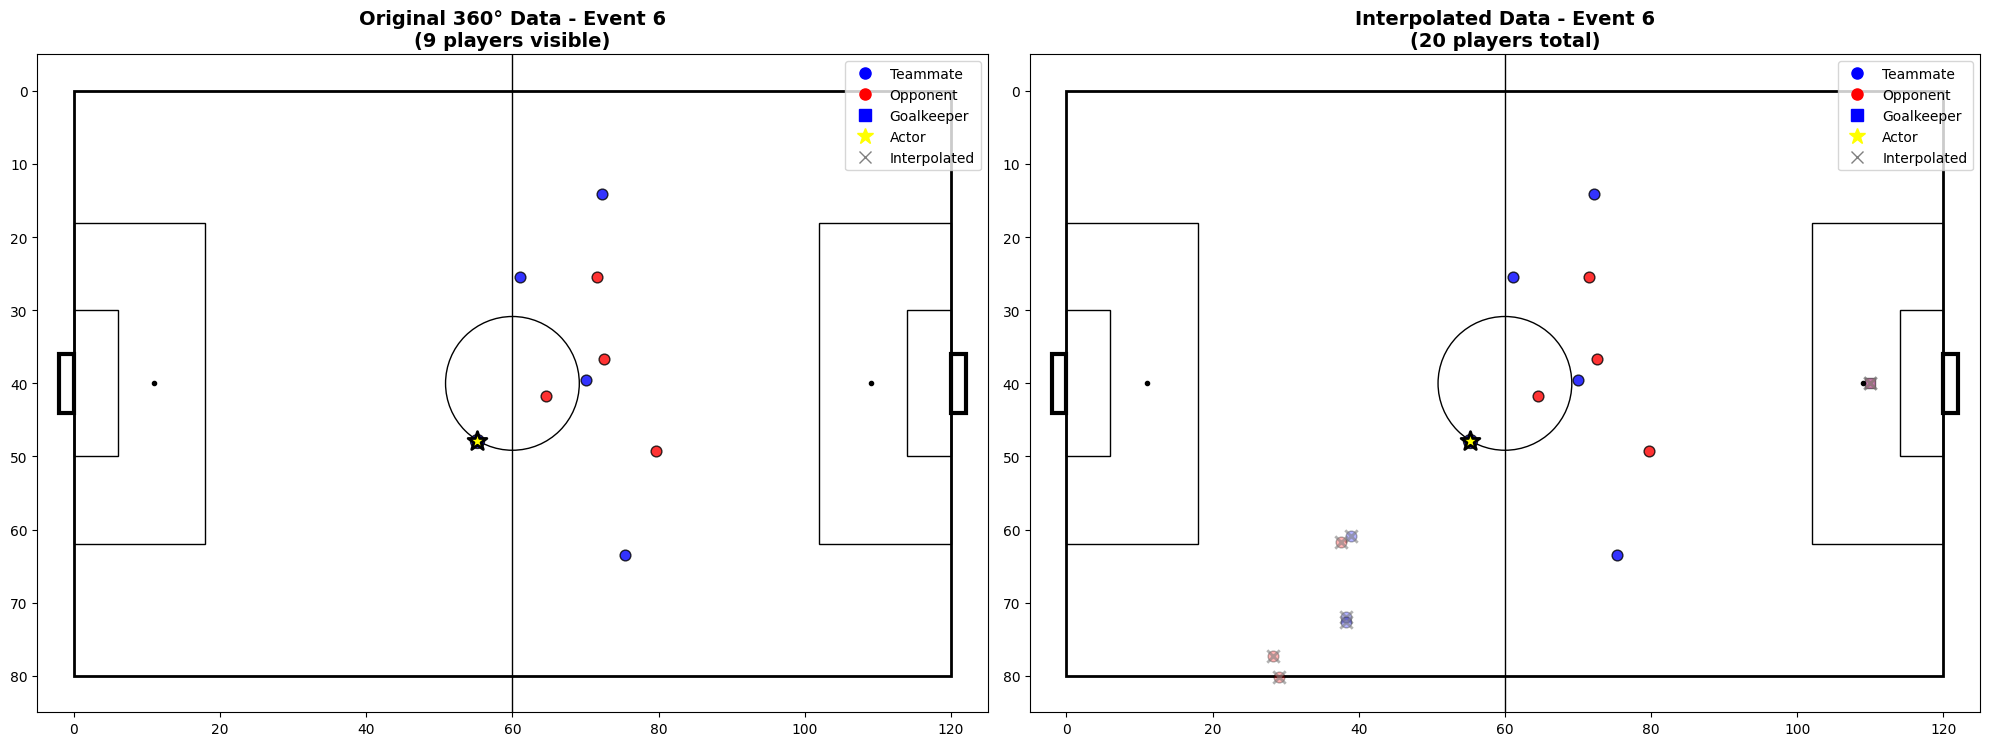


🎨 Creating comparison plot for event 8...


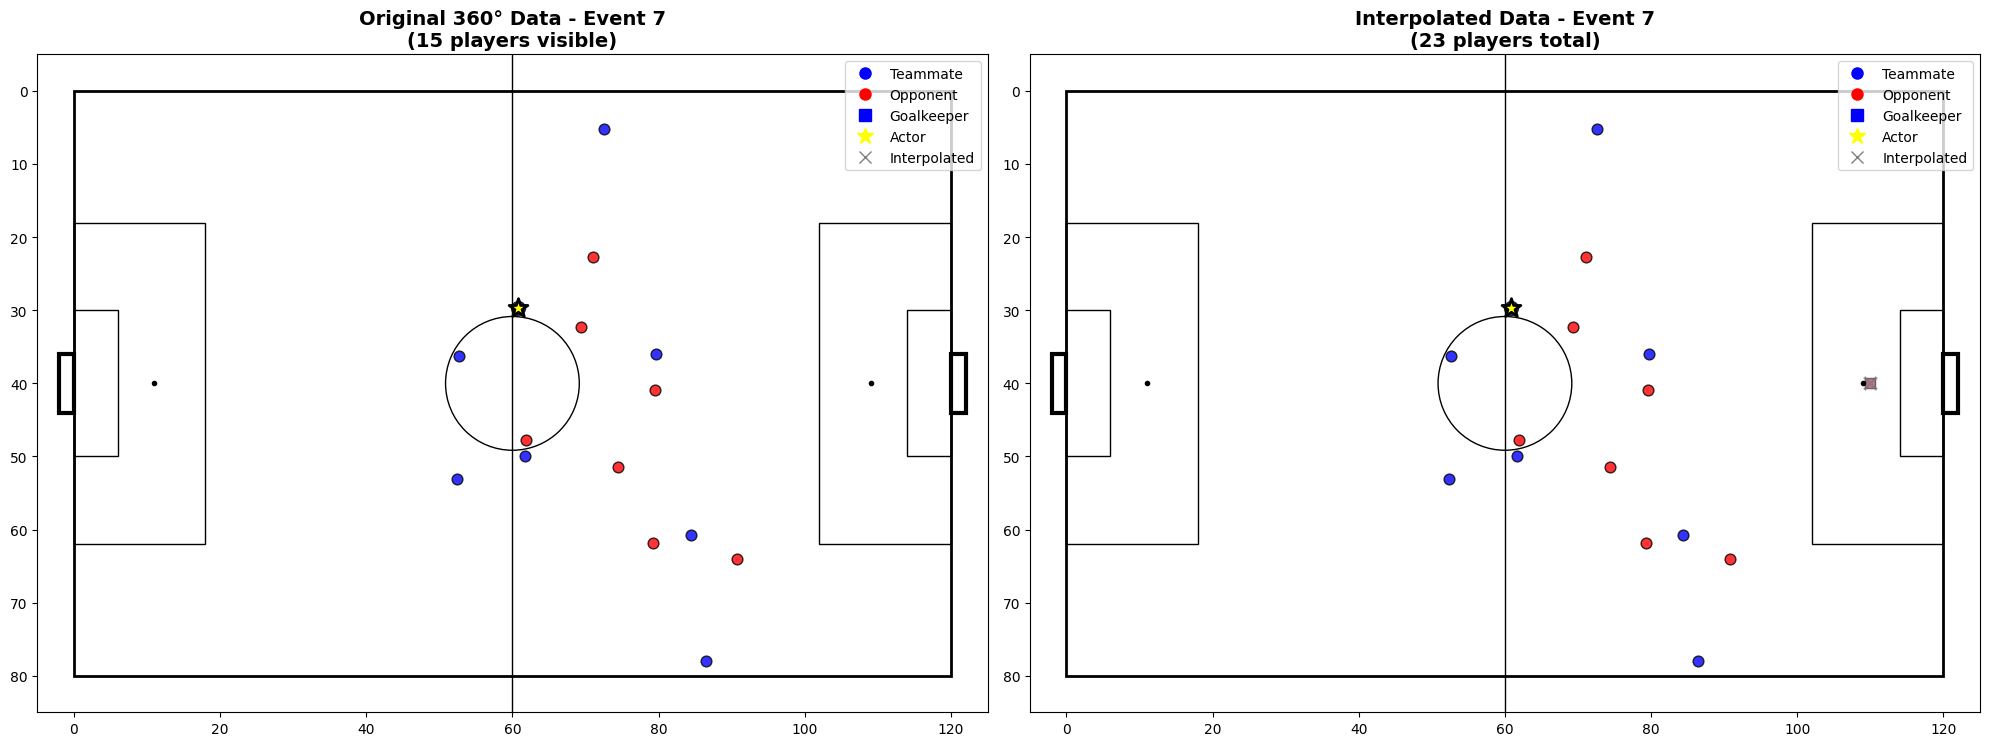


🎨 Creating comparison plot for event 9...


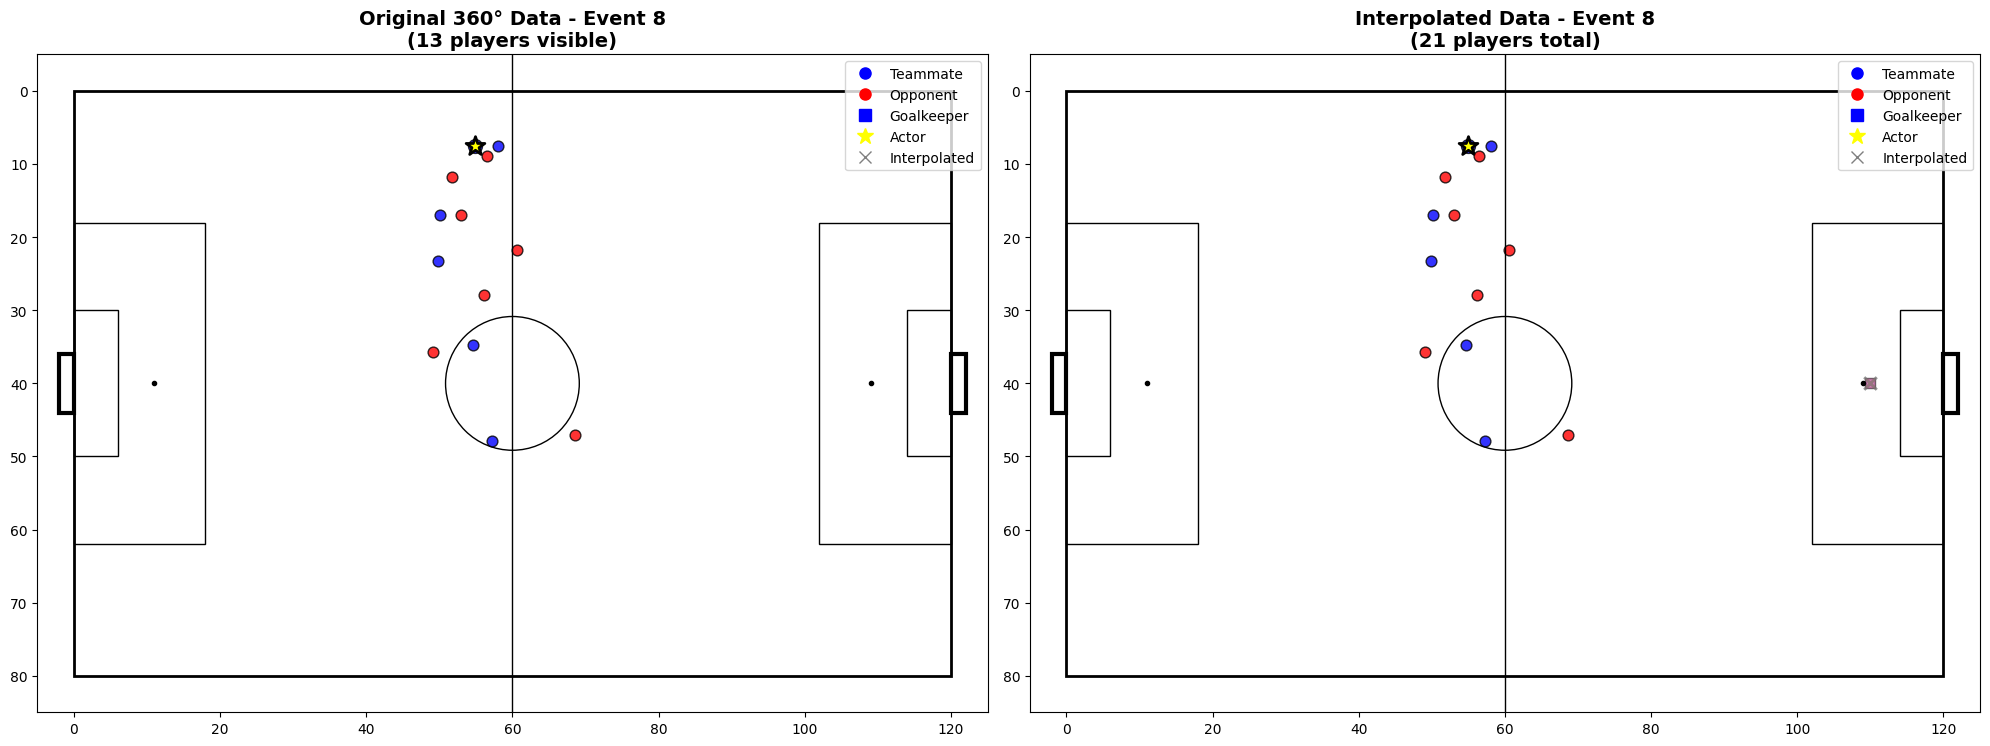


🎨 Creating comparison plot for event 10...


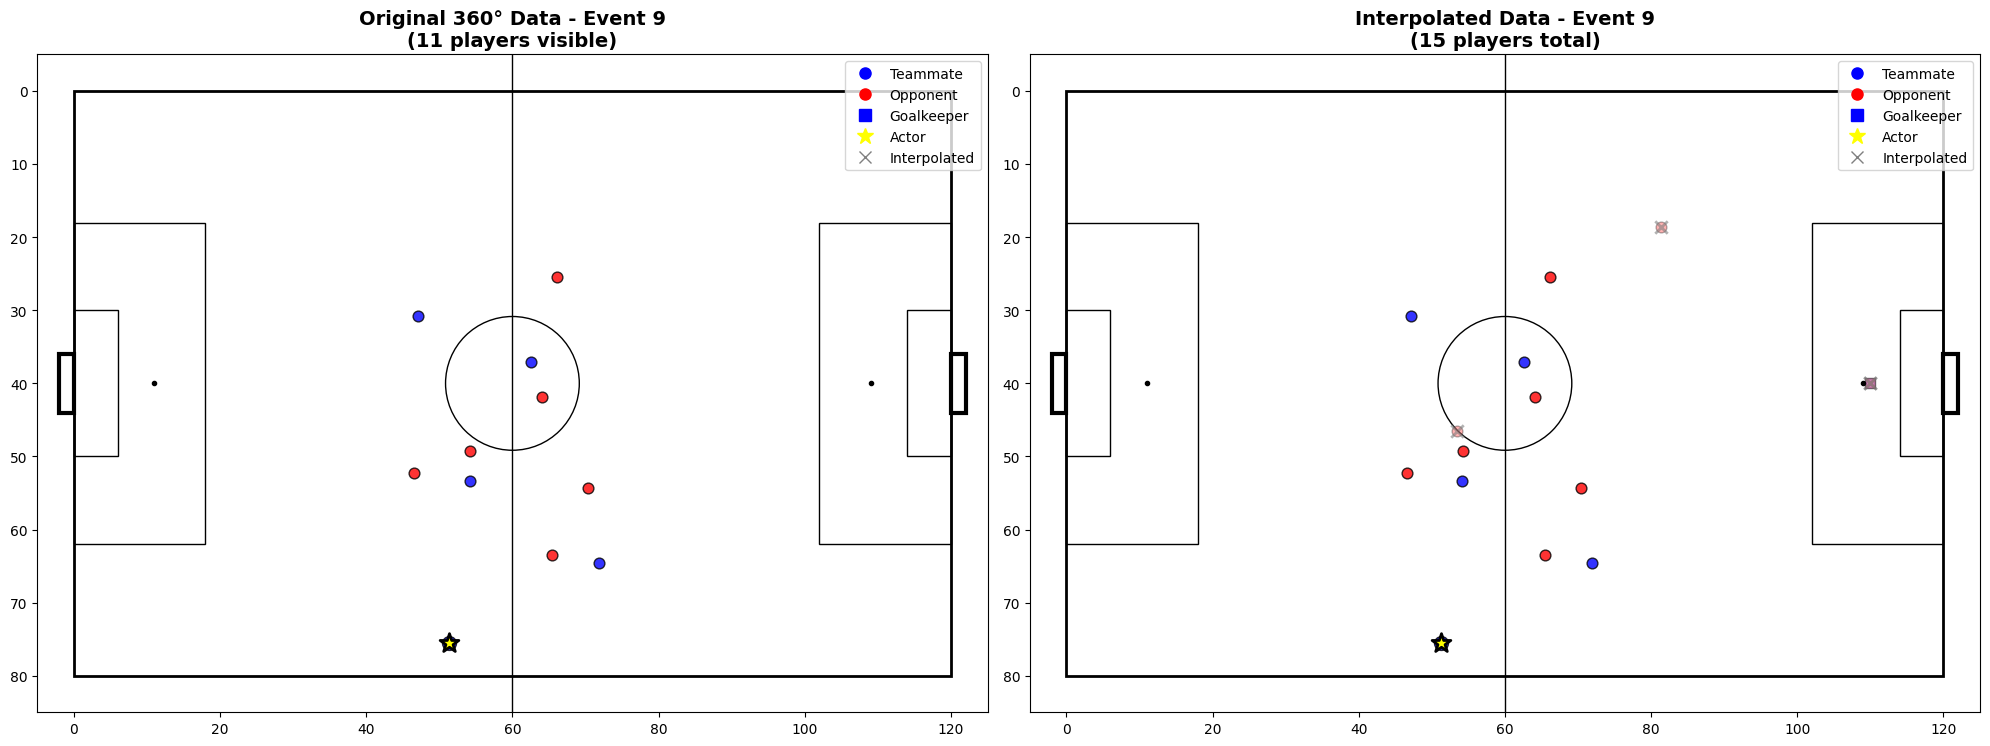


🎯 Summary:
   - Original data: Only visible players from 360° tracking
   - Interpolated data: Complete 22-player positions
   - Blue = Teammates, Red = Opponents
   - Squares = Goalkeepers, Stars = Actors
   - Gray X = Interpolated positions


In [3]:
import json
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Circle
import matplotlib.patches as patches

def draw_pitch(ax):
    """Draw a soccer pitch with proper dimensions (120x80)"""
    # Pitch outline
    ax.add_patch(Rectangle((0, 0), 120, 80, fill=False, color='black', linewidth=2))
    
    # Center line
    ax.axvline(x=60, color='black', linewidth=1)
    
    # Center circle
    center_circle = Circle((60, 40), 9.15, fill=False, color='black', linewidth=1)
    ax.add_patch(center_circle)
    
    # Penalty areas
    ax.add_patch(Rectangle((0, 18), 18, 44, fill=False, color='black', linewidth=1))
    ax.add_patch(Rectangle((102, 18), 18, 44, fill=False, color='black', linewidth=1))
    
    # Six-yard boxes
    ax.add_patch(Rectangle((0, 30), 6, 20, fill=False, color='black', linewidth=1))
    ax.add_patch(Rectangle((114, 30), 6, 20, fill=False, color='black', linewidth=1))
    
    # Goals
    ax.add_patch(Rectangle((-2, 36), 2, 8, fill=False, color='black', linewidth=3))
    ax.add_patch(Rectangle((120, 36), 2, 8, fill=False, color='black', linewidth=3))
    
    # Penalty spots
    ax.plot(11, 40, 'o', color='black', markersize=3)
    ax.plot(109, 40, 'o', color='black', markersize=3)
    
    ax.set_xlim(-5, 125)
    ax.set_ylim(-5, 85)
    ax.set_aspect('equal')
    ax.invert_yaxis()  # StatsBomb convention

def plot_event_comparison(original_data, interpolated_data, event_index=0):
    """Compare original 360° data with interpolated data for a specific event"""
    
    # Get the specific event
    original_event = original_data[event_index]
    interpolated_event = interpolated_data[event_index]
    
    # Extract positions
    orig_positions = []
    interp_positions = []
    
    # Original data (only visible players)
    for player in original_event['freeze_frame']:
        if 'location' in player:
            orig_positions.append({
                'location': player['location'],
                'teammate': player['teammate'],
                'actor': player['actor'],
                'keeper': player['keeper']
            })
    
    # Interpolated data (all 22 players)
    for player in interpolated_event['freeze_frame']:
        if 'location' in player:
            interp_positions.append({
                'location': player['location'],
                'teammate': player['teammate'],
                'actor': player['actor'],
                'keeper': player['keeper'],
                'visible': player.get('visible', True)
            })
    
    # Create comparison plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))
    
    # Plot 1: Original 360° data
    draw_pitch(ax1)
    ax1.set_title(f'Original 360° Data - Event {event_index}\n({len(orig_positions)} players visible)', 
                  fontsize=14, fontweight='bold')
    
    for i, player in enumerate(orig_positions):
        x, y = player['location']
        color = 'blue' if player['teammate'] else 'red'
        marker = 'o' if not player['keeper'] else 's'
        size = 100 if player['actor'] else 60
        
        ax1.scatter(x, y, c=color, marker=marker, s=size, alpha=0.8, edgecolors='black', linewidth=1)
        
        # Highlight actor
        if player['actor']:
            ax1.scatter(x, y, c='yellow', marker='*', s=200, edgecolors='black', linewidth=2)
    
    # Plot 2: Interpolated data
    draw_pitch(ax2)
    ax2.set_title(f'Interpolated Data - Event {event_index}\n({len(interp_positions)} players total)', 
                  fontsize=14, fontweight='bold')
    
    for i, player in enumerate(interp_positions):
        x, y = player['location']
        color = 'blue' if player['teammate'] else 'red'
        marker = 'o' if not player['keeper'] else 's'
        size = 100 if player['actor'] else 60
        alpha = 0.8 if player.get('visible', True) else 0.3
        
        ax2.scatter(x, y, c=color, marker=marker, s=size, alpha=alpha, edgecolors='black', linewidth=1)
        
        # Highlight actor
        if player['actor']:
            ax2.scatter(x, y, c='yellow', marker='*', s=200, edgecolors='black', linewidth=2)
        
        # Show interpolated players with different style
        if not player.get('visible', True):
            ax2.scatter(x, y, c='gray', marker='x', s=80, alpha=0.6, linewidth=2)
    
    # Add legend
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], marker='o', color='blue', linestyle='None', markersize=8, label='Teammate'),
        Line2D([0], [0], marker='o', color='red', linestyle='None', markersize=8, label='Opponent'),
        Line2D([0], [0], marker='s', color='blue', linestyle='None', markersize=8, label='Goalkeeper'),
        Line2D([0], [0], marker='*', color='yellow', linestyle='None', markersize=12, label='Actor'),
        Line2D([0], [0], marker='x', color='gray', linestyle='None', markersize=8, label='Interpolated')
    ]
    
    ax1.legend(handles=legend_elements, loc='upper right')
    ax2.legend(handles=legend_elements, loc='upper right')
    
    plt.tight_layout()
    return fig

def analyze_data_differences(original_data, interpolated_data, num_events=5):
    """Analyze the differences between original and interpolated data"""
    
    print("🔍 INTERPOLATION ANALYSIS")
    print("=" * 50)
    
    for i in range(min(num_events, len(original_data))):
        orig_event = original_data[i]
        interp_event = interpolated_data[i]
        
        # Count players
        orig_players = len(orig_event['freeze_frame'])
        interp_players = len(interp_event['freeze_frame'])
        
        # Count visible vs interpolated
        visible_count = sum(1 for p in interp_event['freeze_frame'] if p.get('visible', True))
        interpolated_count = interp_players - visible_count
        
        print(f"\n📊 Event {i+1} ({orig_event['event_uuid'][:8]}...)")
        print(f"   Original 360° data: {orig_players} players")
        print(f"   Interpolated data: {interp_players} players")
        print(f"   Visible players: {visible_count}")
        print(f"   Interpolated players: {interpolated_count}")
        
        # Check for coordinate differences
        orig_locs = [p['location'] for p in orig_event['freeze_frame'] if 'location' in p]
        interp_locs = [p['location'] for p in interp_event['freeze_frame'] if 'location' in p]
        
        if len(orig_locs) > 0 and len(interp_locs) > 0:
            # Calculate average position difference for visible players
            min_len = min(len(orig_locs), len(interp_locs))
            if min_len > 0:
                orig_array = np.array(orig_locs[:min_len])
                interp_array = np.array(interp_locs[:min_len])
                distances = np.sqrt(np.sum((orig_array - interp_array)**2, axis=1))
                avg_distance = np.mean(distances)
                print(f"   Average position difference: {avg_distance:.2f} units")

def main():
    """Main function to load data and create comparisons"""
    
    # Load the data files
    print("📁 Loading data files...")
    
    with open('/Users/zubair/Desktop/Columbia/Assignments/capstone/Columbia-MSDS-F25-Soccer/interpolation/open-data/data/three-sixty/3788741.json', 'r') as f:
        original_data = json.load(f)
    
    with open('/Users/zubair/Desktop/Columbia/Assignments/capstone/Columbia-MSDS-F25-Soccer/interpolation/Outputs/3788741.json', 'r') as f:
        interpolated_data = json.load(f)
    
    print(f"✅ Loaded {len(original_data)} events from original data")
    print(f"✅ Loaded {len(interpolated_data)} events from interpolated data")
    
    # Analyze differences
    analyze_data_differences(original_data, interpolated_data, num_events=3)
    
    # Create comparison plots for first 2 events
    for i in range(min(10, len(original_data))):
        print(f"\n🎨 Creating comparison plot for event {i+1}...")
        fig = plot_event_comparison(original_data, interpolated_data, event_index=i)
        plt.savefig(f'interpolation_comparison_event_{i+1}.png', dpi=300, bbox_inches='tight')
        plt.show()
    
    print("\n🎯 Summary:")
    print("   - Original data: Only visible players from 360° tracking")
    print("   - Interpolated data: Complete 22-player positions")
    print("   - Blue = Teammates, Red = Opponents")
    print("   - Squares = Goalkeepers, Stars = Actors")
    print("   - Gray X = Interpolated positions")

if __name__ == "__main__":
    main()